# Robotics: a serial robot

Notebook `python/Notebooks/tutorialRobotics.ipynb`.

The Puma560 of `exudyn.robotics.models` as a `Robot`: its kinematics and inverse kinematics without a model, a
trajectory of a joint space and a Cartesian motion with blending, the robot as kinematic tree with the joint control
and the compensation of its dynamics, and the joint coordinates measured by sensors. The outputs below each cell are
those of the last run.

In [1]:
import exudyn as exu
import exudyn.graphics as graphics
from exudyn.robotics import Robot, RobotBase, VRobotBase, RobotTool, VRobotTool
from exudyn.robotics.models import ManipulatorPuma560, LinkDict2Robot
from exudyn.robotics.motion import Trajectory, ProfileConstantAcceleration, ProfileCartesianLinear
from exudyn.interactive import ShowImage
import numpy as np

SC = exu.SystemContainer()
mbs = SC.AddSystem()

## The robot

`LinkDict2Robot` builds a `Robot` from the dictionary of a model: the links by their Denavit-Hartenberg parameters,
masses, centers of mass, inertias, joint limits and the P and D values of the joint control. The robot given as
`robotClass` brings gravity, a base and a tool with their graphics; `initialConfiguration='qn'` starts it in one of
the configurations the model names, the nominal configuration of the Robotics Toolbox with the arm bent forward
(`friction=True` would give the joints the friction of the model).

In [2]:
toolGraphics = [graphics.Cylinder([0,0,-0.06], [0,0,0.02], radius=0.035, color=graphics.color.darkgrey),
                graphics.Brick([0,-0.02,-0.02], [0.03,0.006,0.06], color=graphics.color.lightgrey),
                graphics.Brick([0, 0.02,-0.02], [0.03,0.006,0.06], color=graphics.color.lightgrey)]
baseGraphics = [graphics.Cylinder([0,0,-0.6], [0,0,0.6], radius=0.1, color=graphics.color.grey),
                graphics.CheckerBoard([0.3,0,-0.6], size=1.6, nTiles=8)]
robot = LinkDict2Robot(ManipulatorPuma560(),
                       robotClass=Robot(gravity=[0,0,-9.81],
                                        base=RobotBase(visualization=VRobotBase(graphicsData=baseGraphics)),
                                        tool=RobotTool(HT=exu.HT(translation=[0,0,0.05]),
                                                       visualization=VRobotTool(graphicsData=toolGraphics))),
                       initialConfiguration='qn')
print('links:', robot.NumberOfLinks(), ', q0 =', np.round(robot.q0, 4))

links: 6 , q0 = [ 0.      0.7854 -3.1416  0.      0.7854  0.    ]


## Kinematics without a model

`GetKinematicChain()` gives the kinematics in C++: the tool frame, the Jacobian, the static torques of gravity and the
inverse dynamics, each in a few microseconds. It needs no `mbs`; create it again after the robot is changed.
`ToolHT(q)` is the homogeneous transformation of the tool, `exu.HT`, with `.rotation` and `.translation` in global
coordinates. The analytic inverse kinematics finds all configurations of a tool frame - up to 8 for the Puma560 with
its spherical wrist; with `qReference`, the angles are shifted by multiples of $2\pi$ to be nearest to it and the
nearest one comes first. A pose that cannot be reached gives no solutions.

In [3]:
chain = robot.GetKinematicChain()  #the kinematics in C++, an exudyn.cUtilities.KinematicChain
q0 = robot.q0                      #the initial joint coordinates, here the configuration 'qn'
HT0 = chain.ToolHT(q0)             #the tool frame in q0
print('tool position in q0:', np.round(HT0.translation, 4))
print('static torques in q0:', np.round(chain.StaticTorques(q0), 3))

#the goal: the same rotation of the tool, its position moved by 0.1, 0.2, -0.15 m
HTgoal = exu.HT(rotation=HT0.rotation, translation=HT0.translation + np.array([0.1, 0.2, -0.15]))
solutions = robot.InverseKinematicsAnalytic(HTgoal, qReference=q0)  #one solution per row, nearest to q0 first
print(len(solutions), 'configurations reach the goal; the nearest:', np.round(solutions[0], 4))

tool position in q0: [ 0.6463 -0.1501 -0.0144]
static torques in q0: [ 0.000e+00 -3.164e+01 -6.035e+00 -0.000e+00 -2.800e-02 -0.000e+00]
8 configurations reach the goal; the nearest: [ 0.2882  0.3877 -2.7716  0.3875  0.8514 -0.2628]


## A trajectory

A `Trajectory` gives the joint coordinates, velocities and accelerations in time, `Evaluate(t)` returning `[q, q_t,
q_tt]`. It starts at `initialCoordinates` at `initialTime` and consists of profiles added one after the other, each
starting where the one before ends:

- `ProfileConstantAcceleration(q, duration)` moves all joints to `q` in the given time, accelerating in the first
  half and decelerating in the second (`ProfilePTP` instead computes the duration from maximum velocities and
  accelerations);
- `ProfileCartesianLinear(robot, HT, duration)` moves the tool on a straight line to the frame `HT`, with a smooth
  time law (a polynomial of fifth order by default); the joint coordinates follow from the analytic inverse kinematics
  in the arm configuration of the start.

Here the joints move to the goal of the inverse kinematics, the tool moves on a line and the joints move back to `q0`.
`blendTimeWithNext` lets the next profile start before the present one has ended: in this time the motions of both
are summed, so that the robot passes near the via point without stopping and still reaches the end of the next
profile exactly. `GetTimes` gives the start time and the times at which the profiles end, the blending included;
`GetBlendings` says how close the blended trajectory comes to the via point, with the kinematic chain also for the
tool.

In [4]:
trajectory = Trajectory(initialCoordinates=q0, initialTime=0.2)  #at rest in q0 until 0.2 s
#to the goal in 0.8 s; the next profile starts 0.2 s before this one ends:
trajectory.Add(ProfileConstantAcceleration(solutions[0], 0.8), blendTimeWithNext=0.2)
#the tool 0.2 m along -x on a straight line, its rotation kept, in 0.8 s:
HTline = exu.HT(rotation=HTgoal.rotation, translation=HTgoal.translation + np.array([-0.2, 0, 0]))
trajectory.Add(ProfileCartesianLinear(robot, HTline, 0.8))
trajectory.Add(ProfileConstantAcceleration(q0, 0.8))  #the joints back to q0, stop there
print('profiles end at', np.round(trajectory.GetTimes(), 3), 's')
for d in trajectory.GetBlendings(chain):  #one dict per blending
    print('blending: the tool passes the via point at', round(d['toolMinDistance'], 4), 'm')

profiles end at [0.2 1.  1.6 2.4] s
blending: the tool passes the via point at 0.0082 m


## The model, its control and its sensors

`CreateKinematicTree` builds the robot in minimal coordinates, one `ObjectKinematicTree` with the joint coordinates
in the order of the links, starting in `q0` (`CreateRedundantCoordinateMBS` would build rigid bodies and joints).
`SetControl` gives the PD control of the joints the trajectory: the P and D values of the links pull the joints
towards the coordinates and velocities of the trajectory. `compensation='dynamic'` adds the joint torques of the
inverse dynamics with the velocities and accelerations of the trajectory as a feed-forward, so that the control only
corrects the errors; `'static'` would add only the torques that hold the robot against gravity. `PreStepControl` is
the PreStepUserFunction that evaluates the trajectory and sets these values in every step. `AddSensors` adds one
sensor per output variable, each measuring that quantity for all joints, and returns their numbers in a dict with the
output variables as keys: `Coordinates` are the joint angles, `Force` the joint torques of the control and the
compensation.

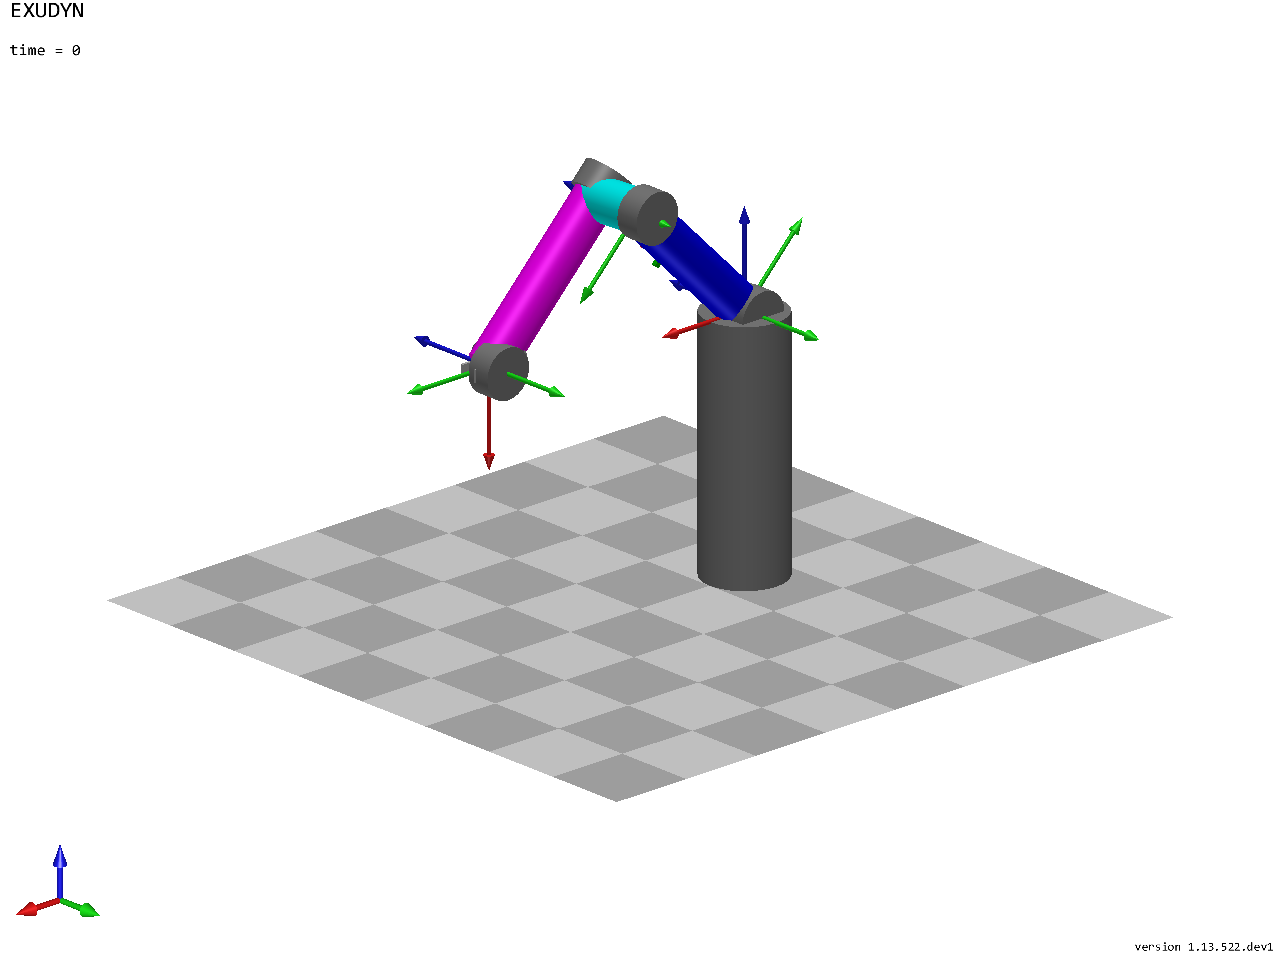

In [5]:
robot.CreateKinematicTree(mbs)                          #the robot in minimal coordinates
robot.SetControl(trajectory, compensation='dynamic')    #PD control towards the trajectory, plus inverse dynamics
mbs.SetPreStepUserFunction(robot.PreStepControl)        #applies the control in every step
sensors = robot.AddSensors(mbs, [exu.OutputVariableType.Coordinates, exu.OutputVariableType.Force])
mbs.Assemble()

SC.visualizationSettings.nodes.show = False
SC.visualizationSettings.view0.scene.drawWorldBasis = False
view = np.array(exu.rigidBodyUtilities.RotationMatrixX(-1.2) @ exu.rigidBodyUtilities.RotationMatrixZ(-2.4)).T
image = ShowImage(SC, size=[1280, 960], modelRotation=view)

In [6]:
tEnd = trajectory.GetTimes()[-1] + 0.3  #the end of the last profile, and 0.3 s at rest
simulationSettings = exu.SimulationSettings()
simulationSettings.timeIntegration.numberOfSteps = int(tEnd/0.002)
simulationSettings.timeIntegration.endTime = tEnd
simulationSettings.timeIntegration.verboseMode = 0
simulationSettings.solution.sensors.writePeriod = 0.01
mbs.SolveDynamic(simulationSettings)

#each row of the sensor data: the time, then the 6 joint angles; compared with q of the trajectory at that time
data = mbs.GetSensorStoredData(sensors[exu.OutputVariableType.Coordinates])
error = max(np.max(np.abs(row[1:] - trajectory.Evaluate(row[0])[0])) for row in data)
print('the largest deviation from the trajectory:', round(error, 6), 'rad')

the largest deviation from the trajectory: 5e-05 rad


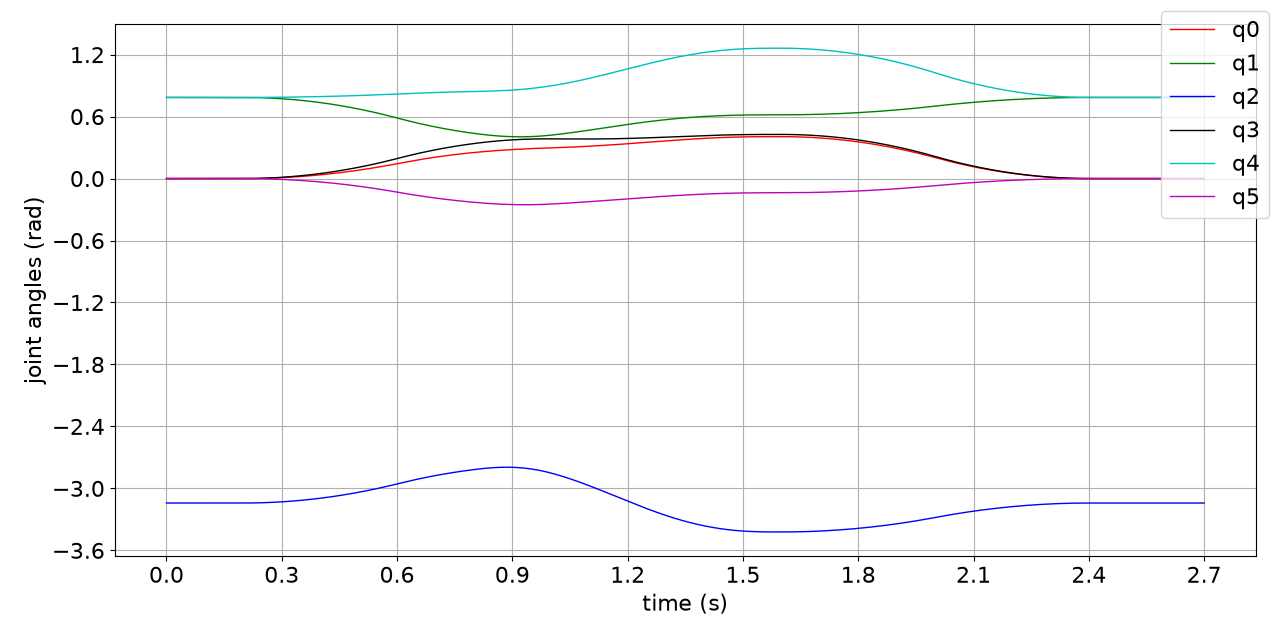

In [7]:
mbs.PlotSensor(sensors[exu.OutputVariableType.Coordinates], components=list(range(6)),
               labels=['q'+str(i) for i in range(6)], yLabel='joint angles (rad)', closeAll=True)

The joint torques of the drives follow from the same sensors, the sum of the PD control and the compensation acting
on each joint. `mbs.SolutionViewer()` replays the motion in the render window. The examples `staubliTX2blending.py`, `serialRobotKinematicTree.py` and `serialRobotTSD.py` go
further.

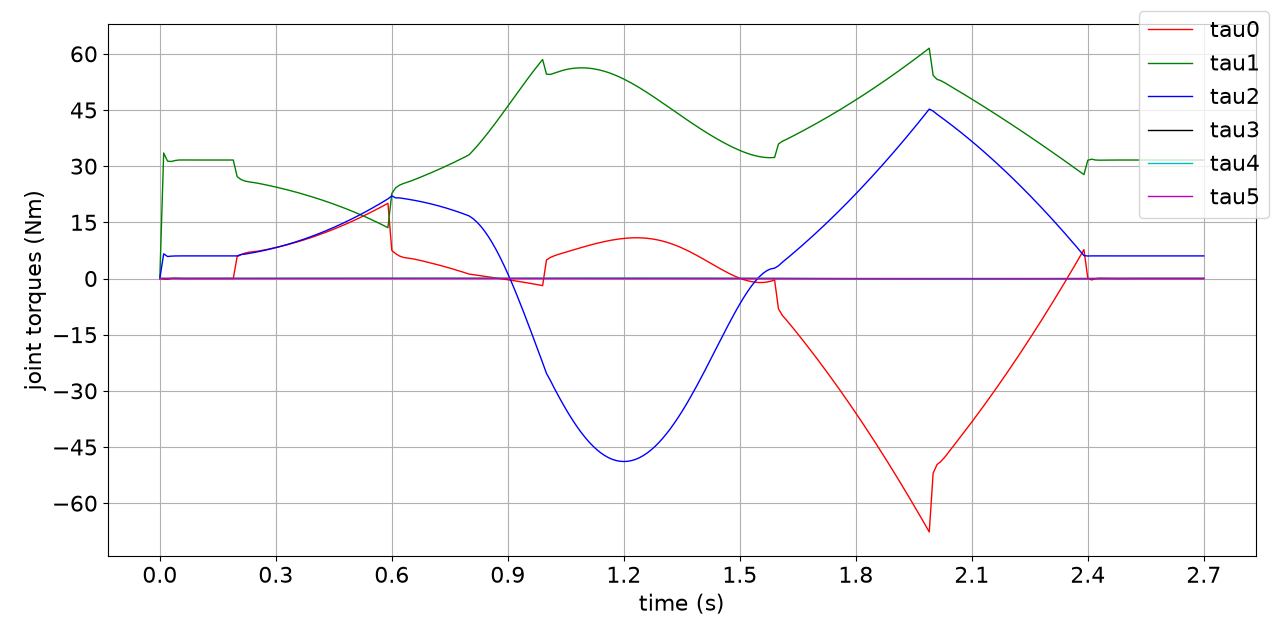

In [8]:
mbs.PlotSensor(sensors[exu.OutputVariableType.Force], components=list(range(6)),
               labels=['tau'+str(i) for i in range(6)], yLabel='joint torques (Nm)')